# The Kang-in Lee Effect — Phase 2: Measuring the Effect

Phase 1 collected the data. This notebook answers the business question with numbers we can defend:

> **How much extra attention did Atlético de Madrid get from Korean-speaking audiences because of the Kang-in Lee signing — compared with what it would have had anyway?**

| # | Analysis | Data | Question it answers |
|---|---|---|---|
| 1 | **Counterfactual model** + block bootstrap | Korean Wikipedia, daily | How many extra visits did Atlético get beyond what the control clubs predict? |
| 2 | **Placebo tests** (fake date, fake club) | Korean Wikipedia | Would the model find an "effect" where there is none? |
| 3 | **Validation case** | Korean Wikipedia, 2023 | Did the same thing happen to PSG when he joined them? |
| 4 | **Difference-in-differences** | YouTube comments | How much did the Korean share of the audience change vs. a control club? |
| 5 | **Country placebo** | Google Trends | Did the effect appear only in Korea (as it should)? |
| 6 | **LinkedIn charts** | All | Three 1080×1350 charts ready for the carousel |

**Inference choices, stated up front:**
- Intervals are 95% bootstrap intervals. Wikipedia uses a **moving-block bootstrap** of model residuals (14-day blocks), because daily errors are autocorrelated and an ordinary bootstrap would understate uncertainty.
- YouTube uses a **video-level cluster bootstrap**: comments under the same video are not independent, so we resample videos, not comments.
- The model intervals do not include parameter uncertainty. The placebo tests are the honest check on whether an effect of this size could appear by chance.

## 0. Setup
Reads the Phase 1 output from your Drive folder `proyecto_kangin`. Change `PROJECT_DIR` if you stored it elsewhere.

In [1]:
import os, math, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter

warnings.filterwarnings('ignore', category=FutureWarning)
pd.set_option('display.width', 160)

PROJECT_DIR = os.environ.get('KANGIN_BASE', '/content/drive/MyDrive/proyecto_kangin/kangin_lee_effect')
if PROJECT_DIR.startswith('/content/drive'):
    from google.colab import drive
    drive.mount('/content/drive')

BASE = Path(PROJECT_DIR)
RAW, PROC = BASE / 'data' / 'raw', BASE / 'data' / 'processed'
OUT = BASE / 'phase2'
FIG = OUT / 'figures'
FIG.mkdir(parents=True, exist_ok=True)
assert (RAW / 'wikipedia_pageviews.csv').exists(), f'Phase 1 data not found in {RAW}'
print('Reading from', BASE)

CHART_LANG = 'es'     # 'es' or 'en' — language of the final LinkedIn charts
AUTHOR = 'Miguel R.'  # signature on the charts
N_BOOT = 2000
SEED = 7

Mounted at /content/drive
Reading from /content/drive/MyDrive/proyecto_kangin/kangin_lee_effect


In [2]:
# ---------- Study design (same as Phase 1) ----------
RUMOURS = '2026-06-09'
SIGNING = '2026-07-25'
WORLD_CUP_2026 = ('2026-06-11', '2026-07-19')
PRE_PERIOD = ('2026-01-01', '2026-05-31')
CONTROLS = ['real_madrid', 'barcelona', 'real_sociedad', 'villarreal']
LABEL = {'atletico': 'Atlético de Madrid', 'psg': 'PSG', 'real_madrid': 'Real Madrid', 'barcelona': 'FC Barcelona',
         'real_sociedad': 'Real Sociedad', 'villarreal': 'Villarreal', 'mallorca': 'RCD Mallorca', 'kangin_lee': 'Kang-in Lee'}

# ---------- Chart style ----------
RED, BLUE, GREY, INK, MUTED = '#CB3524', '#2E6DB4', '#A3A3A3', '#1A1A1A', '#6B6B6B'
plt.rcParams.update({
    'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.alpha': 0.22, 'grid.linewidth': 0.8, 'axes.edgecolor': '#BBBBBB',
    'axes.titleweight': 'bold', 'axes.titlelocation': 'left', 'font.size': 10.5,
    'legend.frameon': False, 'axes.labelcolor': INK, 'xtick.color': MUTED, 'ytick.color': MUTED,
})

def t(es, en):
    return es if CHART_LANG == 'es' else en

def num(x, d=0):
    s = f'{x:,.{d}f}'
    return s.replace(',', 'X').replace('.', ',').replace('X', '.') if CHART_LANG == 'es' else s

def pct(x, d=1):
    return num(x, d) + '%'

def save(fig, name):
    p = FIG / f'{name}.png'
    fig.savefig(p, dpi=fig.dpi, bbox_inches=None if fig.get_size_inches()[0] == 10.8 else 'tight')
    print('Saved', p)

def shade_events(ax, lo=None, hi=None):
    lo, hi = pd.Timestamp(lo or '1900-01-01'), pd.Timestamp(hi or '2100-01-01')
    w0, w1 = map(pd.Timestamp, WORLD_CUP_2026)
    if w1 >= lo and w0 <= hi:
        ax.axvspan(w0, w1, color='#4A90D9', alpha=0.07, lw=0)
    for d in (RUMOURS, SIGNING):
        if lo <= pd.Timestamp(d) <= hi:
            ax.axvline(pd.Timestamp(d), color='#444444', lw=0.9, ls='--', alpha=0.7)

In [3]:
wiki = pd.read_csv(RAW / 'wikipedia_pageviews.csv', parse_dates=['date'])
ko = wiki[wiki.lang == 'ko'].pivot_table(index='date', columns='entity', values='views').asfreq('D').fillna(0)
DATA_END = ko.index.max()

videos = pd.read_csv(RAW / 'youtube_videos.csv')
COLLECTION = pd.to_datetime(videos.published_at, utc=True).max().normalize()

trends = pd.read_csv(RAW / 'google_trends.csv', parse_dates=['date'])
pv_all = pd.read_csv(PROC / 'youtube_korean_share_per_video.csv')
pv_all['published_at'] = pd.to_datetime(pv_all.published_at, utc=True)

print(f'Wikipedia: {ko.index.min().date()} → {DATA_END.date()} | entities: {list(ko.columns)}')
print(f'YouTube collection date (latest upload): {COLLECTION.date()} | videos with comments: {len(pv_all):,}')
print(f'Trends rows: {len(trends):,}')

Wikipedia: 2022-01-01 → 2026-11-01 | entities: ['atletico', 'barcelona', 'kangin_lee', 'mallorca', 'psg', 'real_madrid', 'real_sociedad', 'villarreal']
YouTube collection date (latest upload): 2026-11-02 | videos with comments: 3,295
Trends rows: 11,256


## 1. Counterfactual model — Korean Wikipedia

**Idea:** before the rumours, the daily visits to Atlético's Korean page moved together with the visits to the control clubs' pages (general interest in Spanish football in Korea, LaLiga matchdays, the World Cup…). We learn that relationship in the pre-period and use it to predict what Atlético **would have had** after June 2026 without the signing. The gap between actual and predicted is the effect.

**Model:** `log(1 + views_Atlético) ~ log(1 + views_controls) + day of week`, fitted by least squares on **Jan 2025 – May 2026**.

- Controls: Real Madrid, Barcelona, Real Sociedad, Villarreal. PSG and Kang-in Lee's own page are excluded because the treatment affects them.
- The World Cup is not a problem for this design: it lifts the controls too, so the model "expects" a World Cup bump for Atlético and only the excess is attributed to the signing.

**Windows reported:**
| Window | Dates | Meaning |
|---|---|---|
| Rumours & World Cup | 9 Jun – 24 Jul | Anticipation |
| Signing month | 25 Jul – 31 Aug | Peak |
| Persistence | 1 Sep – end of data | **The business number:** what remains once the news fades |

In [4]:
def block_bootstrap(resid, n_out, n_boot, block, rng):
    n_blocks = int(np.ceil(n_out / block))
    starts = rng.integers(0, len(resid) - block + 1, size=(n_boot, n_blocks))
    return resid[starts[..., None] + np.arange(block)].reshape(n_boot, -1)[:, :n_out]

def fit_counterfactual(data, target, controls, fit_period, post_start, post_end,
                       n_boot=N_BOOT, block=14, seed=SEED):
    d = data.loc[fit_period[0]:post_end, [target] + controls].fillna(0)
    idx = d.index
    X = np.log1p(d[controls])
    dow = pd.get_dummies(idx.dayofweek, prefix='dow', drop_first=True, dtype=float)
    dow.index = idx
    X = pd.concat([X, dow], axis=1)
    X.insert(0, 'const', 1.0)
    y = np.log1p(d[target])
    fit = idx <= pd.Timestamp(fit_period[1])
    post = idx >= pd.Timestamp(post_start)

    beta, *_ = np.linalg.lstsq(X[fit].values, y[fit].values, rcond=None)
    pred = X.values @ beta
    resid = y[fit].values - pred[fit]
    rng = np.random.default_rng(seed)
    cf = np.expm1(pred[post] + block_bootstrap(resid, int(post.sum()), n_boot, block, rng))

    actual = d[target]
    return {
        'target': target,
        'r2_log': 1 - resid.var() / y[fit].var(),
        'mape': float(np.mean(np.abs(np.expm1(pred[fit]) - actual[fit]) / np.maximum(actual[fit], 1))),
        'fitted': pd.DataFrame({'actual': actual[fit], 'fitted': np.expm1(pred[fit])}),
        'post': pd.DataFrame({'actual': actual[post], 'cf_median': np.median(cf, 0),
                              'cf_lo': np.percentile(cf, 2.5, 0), 'cf_hi': np.percentile(cf, 97.5, 0)}),
        'sims': pd.DataFrame(cf.T, index=idx[post]),
        'coef': pd.Series(beta, index=X.columns),
    }

def window_effect(res, start, end):
    s = res['sims'].loc[start:end]
    if s.empty:
        return None
    a = res['post']['actual'].loc[start:end].sum()
    cf_tot = s.sum(0).to_numpy()
    extra, lift = a - cf_tot, a / cf_tot - 1
    q = lambda v, p: float(np.percentile(v, p))
    return {'days': len(s), 'actual': a, 'expected': q(cf_tot, 50),
            'extra': q(extra, 50), 'extra_lo': q(extra, 2.5), 'extra_hi': q(extra, 97.5),
            'lift_pct': 100 * q(lift, 50), 'lift_lo': 100 * q(lift, 2.5), 'lift_hi': 100 * q(lift, 97.5),
            'multiple': a / q(cf_tot, 50)}

def effects_table(res, windows):
    rows = {name: window_effect(res, *w) for name, w in windows.items()}
    return pd.DataFrame({k: v for k, v in rows.items() if v}).T

END = str(DATA_END.date())
WINDOWS = {
    'Rumours & World Cup': (RUMOURS, '2026-07-24'),
    'Signing month': (SIGNING, '2026-08-31'),
    'Persistence (Sep →)': ('2026-09-01', END),
    'Total since rumours': (RUMOURS, END),
}
FIT_PERIOD = ('2025-01-01', PRE_PERIOD[1])

main = fit_counterfactual(ko, 'atletico', CONTROLS, FIT_PERIOD, RUMOURS, END)
print(f"Pre-period fit: R² (log scale) = {main['r2_log']:.2f} | MAPE = {main['mape']:.0%}")
eff_main = effects_table(main, WINDOWS)
eff_main.round(1)

Pre-period fit: R² (log scale) = 0.18 | MAPE = 42%


,days,actual,expected,extra,extra_lo,extra_hi,lift_pct,lift_lo,lift_hi,multiple
Rumours & World Cup,46.0,11643.0,1126.4,10516.6,10078.7,10797.3,933.7,644.3,1276.7,10.3
Signing month,38.0,11811.0,835.5,10975.5,10610.1,11191.0,1313.6,883.5,1805.0,14.1
Persistence (Sep →),62.0,3985.0,1091.0,2894.0,2543.5,3127.2,265.2,176.4,364.6,3.7
Total since rumours,146.0,27439.0,3098.3,24340.7,23702.9,24847.0,785.6,634.4,958.6,8.9


**How to read the table:** `extra` = visits above the counterfactual (with 95% interval); `lift_pct` = how much higher than expected, in %; `multiple` = actual ÷ expected.

The persistence row is the one that matters for the business story: a spike around the news is expected, a lasting lift is what a sponsor or the marketing department pays for.

Saved /content/drive/MyDrive/proyecto_kangin/kangin_lee_effect/phase2/figures/diag_01_counterfactual.png


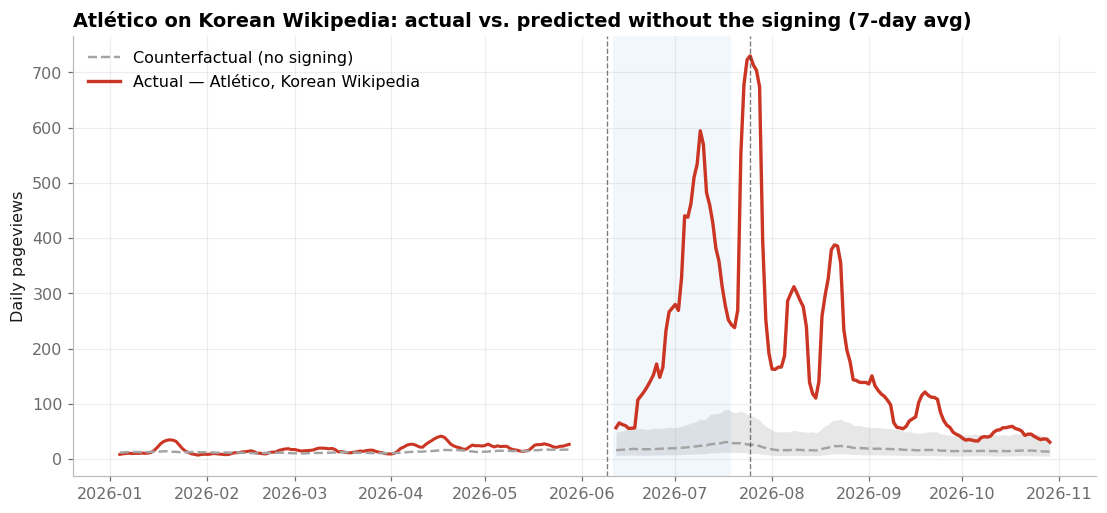

In [5]:
fig, ax = plt.subplots(figsize=(12, 5.2))
f = main['fitted'].loc['2026-01-01':].rolling(7, center=True).mean()
p = main['post'].rolling(7, center=True).mean()
ax.plot(f.index, f.actual, color=RED, lw=2)
ax.plot(f.index, f.fitted, color=GREY, lw=1.6, ls='--')
ax.fill_between(p.index, p.cf_lo, p.cf_hi, color=GREY, alpha=0.25, lw=0)
ax.plot(p.index, p.cf_median, color=GREY, lw=1.6, ls='--', label='Counterfactual (no signing)')
ax.plot(p.index, p.actual, color=RED, lw=2.2, label='Actual — Atlético, Korean Wikipedia')
shade_events(ax, '2026-01-01', END)
ax.set_title('Atlético on Korean Wikipedia: actual vs. predicted without the signing (7-day avg)')
ax.set_ylabel('Daily pageviews')
ax.legend(loc='upper left')
save(fig, 'diag_01_counterfactual')
plt.show()

## 2. Placebo tests

A model that "finds" effects everywhere is useless. Two checks:

1. **Placebo in time:** the same model, pretending the signing happened on the same dates **one year earlier** (June 2025), when nothing happened. The lift should be close to zero, with an interval that includes zero.
2. **Placebo in space:** the same model applied to **each control club** as if it had signed Kang-in Lee (using the other controls as its comparison). Their "effects" show the size of effect the model produces by chance. Atlético's should be far outside that range.

With only four control clubs this is a descriptive check, not a formal p-value (the smallest possible p-value would be 1/5 = 0.2). We report it as "Atlético's effect is N times the largest placebo".

In [6]:
# 2a. Placebo in time: same calendar, one year earlier
shift = lambda d: str((pd.Timestamp(d) - pd.DateOffset(years=1)).date())
WINDOWS_2025 = {k: (shift(a), shift(b)) for k, (a, b) in WINDOWS.items()}
placebo_time = fit_counterfactual(ko, 'atletico', CONTROLS, ('2024-01-01', '2025-05-31'),
                                  WINDOWS_2025['Total since rumours'][0], WINDOWS_2025['Total since rumours'][1])
eff_time = effects_table(placebo_time, WINDOWS_2025)
print('Placebo in time (fake signing in 2025):')
display(eff_time[['extra', 'extra_lo', 'extra_hi', 'lift_pct', 'lift_lo', 'lift_hi']].round(1))

# 2b. Placebo in space: each control club "treated"
rows = []
for c in CONTROLS:
    others = [x for x in CONTROLS if x != c]
    r = fit_counterfactual(ko, c, others, FIT_PERIOD, RUMOURS, END)
    for w in ['Signing month', 'Persistence (Sep →)']:
        e = window_effect(r, *WINDOWS[w])
        rows.append({'club': LABEL[c], 'window': w, 'lift_pct': e['lift_pct'], 'lift_lo': e['lift_lo'], 'lift_hi': e['lift_hi']})
for w in ['Signing month', 'Persistence (Sep →)']:
    e = eff_main.loc[w]
    rows.append({'club': 'Atlético de Madrid (treated)', 'window': w,
                 'lift_pct': e.lift_pct, 'lift_lo': e.lift_lo, 'lift_hi': e.lift_hi})
placebo_space = pd.DataFrame(rows)
display(placebo_space.pivot(index='club', columns='window', values='lift_pct').round(0))

for w in ['Signing month', 'Persistence (Sep →)']:
    pl = placebo_space[(placebo_space.window == w) & ~placebo_space.club.str.contains('treated')]
    atl = eff_main.loc[w, 'lift_pct']
    biggest = pl.lift_pct.abs().max()
    print(f'{w}: Atlético lift {atl:+.0f}% vs. largest placebo {biggest:.0f}% → {atl / biggest:.1f}× larger')

Placebo in time (fake signing in 2025):


,extra,extra_lo,extra_hi,lift_pct,lift_lo,lift_hi
Rumours & World Cup,50.0,-246.2,221.4,7.0,-24.4,40.8
Signing month,426.9,91.3,581.5,67.5,9.4,121.8
Persistence (Sep →),-59.7,-380.5,145.2,-6.7,-31.4,21.1
Total since rumours,372.2,-142.1,753.8,16.3,-5.1,39.6


window,Persistence (Sep →),Signing month
club,,
Atlético de Madrid (treated),265.0,1314.0
FC Barcelona,7.0,16.0
Real Madrid,-10.0,-1.0
Real Sociedad,1.0,75.0
Villarreal,47.0,219.0


Signing month: Atlético lift +1314% vs. largest placebo 219% → 6.0× larger
Persistence (Sep →): Atlético lift +265% vs. largest placebo 47% → 5.6× larger


Saved /content/drive/MyDrive/proyecto_kangin/kangin_lee_effect/phase2/figures/diag_02_placebo_space.png


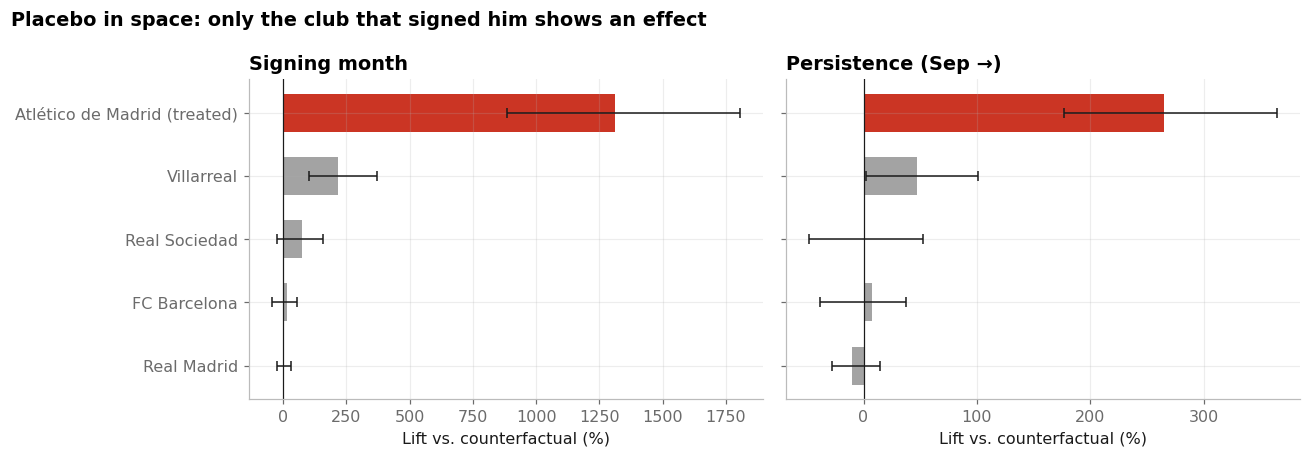

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, w in zip(axes, ['Signing month', 'Persistence (Sep →)']):
    d = placebo_space[placebo_space.window == w].sort_values('lift_pct')
    colors = [RED if 'treated' in c else GREY for c in d.club]
    ax.barh(d.club, d.lift_pct, color=colors, height=0.6)
    ax.errorbar(d.lift_pct, d.club, xerr=[d.lift_pct - d.lift_lo, d.lift_hi - d.lift_pct],
                fmt='none', ecolor=INK, elinewidth=1, capsize=3)
    ax.axvline(0, color=INK, lw=0.8)
    ax.set_title(w)
    ax.set_xlabel('Lift vs. counterfactual (%)')
fig.suptitle('Placebo in space: only the club that signed him shows an effect', x=0.01, ha='left', fontweight='bold')
fig.tight_layout()
save(fig, 'diag_02_placebo_space')
plt.show()

## 3. Validation case: Mallorca → PSG, July 2023

The same model, run on PSG's Korean Wikipedia page around his first big transfer. If the pattern repeats (peak plus a lasting lift), the 2026 result is not a one-off.

⚠️ Confounder: PSG toured Asia in summer 2023, which also raised its profile in Korea. The validation supports the pattern but does not isolate the player effect as cleanly as 2026.

Pre-period fit: R² (log) = 0.21 | MAPE = 33%


,actual,expected,extra,lift_pct,lift_lo,lift_hi,multiple
Transfer → end Aug 2023,36145.0,7485.5,28659.5,382.9,208.7,508.1,4.8
Sep – Dec 2023,23315.0,17077.4,6237.6,36.5,2.6,62.8,1.4


Saved /content/drive/MyDrive/proyecto_kangin/kangin_lee_effect/phase2/figures/diag_03_validation_2023.png


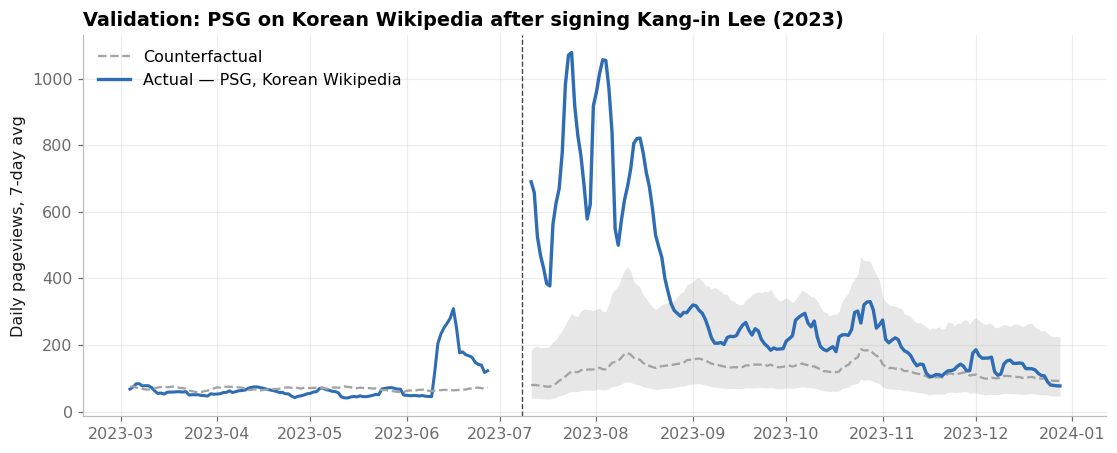

In [8]:
WINDOWS_2023 = {'Transfer → end Aug 2023': ('2023-07-08', '2023-08-31'),
                'Sep – Dec 2023': ('2023-09-01', '2023-12-31')}
val = fit_counterfactual(ko, 'psg', CONTROLS, ('2022-01-01', '2023-06-30'), '2023-07-08', '2023-12-31')
print(f"Pre-period fit: R² (log) = {val['r2_log']:.2f} | MAPE = {val['mape']:.0%}")
eff_val = effects_table(val, WINDOWS_2023)
display(eff_val[['actual', 'expected', 'extra', 'lift_pct', 'lift_lo', 'lift_hi', 'multiple']].round(1))

fig, ax = plt.subplots(figsize=(12, 4.5))
f = val['fitted'].loc['2023-03-01':].rolling(7, center=True).mean()
p = val['post'].rolling(7, center=True).mean()
ax.plot(f.index, f.actual, color=BLUE, lw=2)
ax.plot(f.index, f.fitted, color=GREY, ls='--', lw=1.5)
ax.fill_between(p.index, p.cf_lo, p.cf_hi, color=GREY, alpha=0.25, lw=0)
ax.plot(p.index, p.cf_median, color=GREY, ls='--', lw=1.5, label='Counterfactual')
ax.plot(p.index, p.actual, color=BLUE, lw=2.2, label='Actual — PSG, Korean Wikipedia')
ax.axvline(pd.Timestamp('2023-07-08'), color='#444444', ls='--', lw=0.9)
ax.set_title('Validation: PSG on Korean Wikipedia after signing Kang-in Lee (2023)')
ax.set_ylabel('Daily pageviews, 7-day avg')
ax.legend(loc='upper left')
save(fig, 'diag_03_validation_2023')
plt.show()

## 4. YouTube — who is in the comments? (difference-in-differences)

**Clean-up first:** videos uploaded in the last 14 days before collection have not completed their comment window, so they are dropped (this is the artificial "drop to zero" at the end of the Phase 1 chart).

**Periods:** pre = Jan–May 2026; post = from the signing (25 Jul). Jun–Jul is a transition period and is left out of the comparison.

**Difference-in-differences (percentage points):**
`(Atlético post − Atlético pre) − (Real Madrid post − Real Madrid pre)`
Real Madrid is the control: same league, a big Asian audience, no Korean signing. Intervals come from resampling **videos** (cluster bootstrap).

In [9]:
CUTOFF = COLLECTION - pd.Timedelta(days=14)
pv = pv_all[pv_all.published_at <= CUTOFF].copy()
pv['period'] = np.select([pv.published_at < pd.Timestamp('2026-06-01', tz='UTC'),
                          pv.published_at >= pd.Timestamp(SIGNING, tz='UTC')], ['pre', 'post'], 'transition')
pv['month'] = pv.published_at.dt.tz_convert(None).dt.to_period('M')
print(f'Dropped {len(pv_all) - len(pv)} videos uploaded after {CUTOFF.date()} (incomplete 14-day window).')

def share_boot(df, col='n_ko_strict', n=N_BOOT, seed=SEED):
    if len(df) == 0:
        return {'share': np.nan, 'lo': np.nan, 'hi': np.nan, 'videos': 0, 'comments': 0, 'ko': 0, 'sample': np.full(n, np.nan)}
    k, tt = df[col].to_numpy(float), df['n_text'].to_numpy(float)
    idx = np.random.default_rng(seed).integers(0, len(df), (n, len(df)))
    s = k[idx].sum(1) / np.maximum(tt[idx].sum(1), 1)
    return {'share': k.sum() / tt.sum(), 'lo': np.percentile(s, 2.5), 'hi': np.percentile(s, 97.5),
            'videos': len(df), 'comments': int(tt.sum()), 'ko': int(k.sum()), 'sample': s}

B = {(e, p): share_boot(pv[(pv.entity == e) & (pv.period == p)])
     for e in ['atletico', 'psg', 'real_madrid'] for p in ['pre', 'post']}
yt_table = pd.DataFrame([{'club': LABEL[e], 'period': p, 'share_%': 100 * b['share'],
                          'ci_lo_%': 100 * b['lo'], 'ci_hi_%': 100 * b['hi'],
                          'videos': b['videos'], 'comments': b['comments'], 'korean_comments': b['ko']}
                         for (e, p), b in B.items()])
display(yt_table.round(2))

did = 100 * ((B['atletico', 'post']['sample'] - B['atletico', 'pre']['sample'])
             - (B['real_madrid', 'post']['sample'] - B['real_madrid', 'pre']['sample']))
DID = {'pp': float(np.median(did)), 'lo': float(np.percentile(did, 2.5)), 'hi': float(np.percentile(did, 97.5))}
print(f"\nDifference-in-differences: {DID['pp']:+.1f} pp (95% CI {DID['lo']:+.1f} to {DID['hi']:+.1f})")

Dropped 184 videos uploaded after 2026-10-19 (incomplete 14-day window).


,club,period,share_%,ci_lo_%,ci_hi_%,videos,comments,korean_comments
0,Atlético de Madrid,pre,0.18,0.11,0.28,685,11355,21
1,Atlético de Madrid,post,24.39,16.59,31.25,375,8640,2107
2,PSG,pre,0.67,0.49,0.87,539,46623,314
3,PSG,post,2.01,0.12,5.70,269,25432,511
4,Real Madrid,pre,0.08,0.06,0.10,502,97137,76
5,Real Madrid,post,0.14,0.06,0.31,367,69151,100



Difference-in-differences: +23.7 pp (95% CI +16.3 to +31.1)


In [10]:
# Who is the audience following — the player or the club?
def share_row(name, df):
    b = share_boot(df)
    return {'segment': name, 'share_%': 100 * b['share'], 'ci_lo_%': 100 * b['lo'], 'ci_hi_%': 100 * b['hi'],
            'videos': b['videos'], 'comments': b['comments']}

atl, psg = pv[pv.entity == 'atletico'], pv[pv.entity == 'psg']
segments = pd.DataFrame([
    share_row('Atlético · pre · all videos', atl[atl.period == 'pre']),
    share_row('Atlético · post · videos featuring Lee', atl[(atl.period == 'post') & atl.mentions_lee]),
    share_row('Atlético · post · videos WITHOUT Lee', atl[(atl.period == 'post') & ~atl.mentions_lee]),
    share_row('PSG · pre · videos without Lee', psg[(psg.period == 'pre') & ~psg.mentions_lee]),
    share_row('PSG · post · videos without Lee', psg[(psg.period == 'post') & ~psg.mentions_lee]),
])
display(segments.round(2))

pre_all = segments.iloc[0]['share_%']
no_lee = segments.iloc[2]['share_%']
print(f'Atlético videos without Lee: {no_lee:.1f}% Korean comments vs {pre_all:.2f}% before the signing → ×{no_lee / pre_all:.0f}')

,segment,share_%,ci_lo_%,ci_hi_%,videos,comments
0,Atlético · pre · all videos,0.18,0.11,0.28,685,11355
1,Atlético · post · videos featuring Lee,54.88,46.83,61.80,36,2952
2,Atlético · post · videos WITHOUT Lee,8.56,6.59,10.77,339,5688
3,PSG · pre · videos without Lee,0.46,0.39,0.55,526,45403
4,PSG · post · videos without Lee,0.18,0.10,0.28,268,24760


Atlético videos without Lee: 8.6% Korean comments vs 0.18% before the signing → ×46


,entity,month,share_%,lo,hi,videos,korean_comments,partial
0,atletico,2026-01,0.12,0.00,0.32,134,2,False
1,atletico,2026-02,0.20,0.04,0.51,134,5,False
2,atletico,2026-03,0.15,0.00,0.36,147,3,False
3,atletico,2026-04,0.12,0.03,0.28,139,4,False
4,atletico,2026-05,0.34,0.11,0.63,131,7,False
5,atletico,2026-06,0.99,0.00,3.08,103,7,False
6,atletico,2026-07,11.67,2.94,21.09,103,152,False
7,atletico,2026-08,33.41,21.66,42.34,141,1528,False
8,atletico,2026-09,11.24,7.69,15.08,133,315,False
9,atletico,2026-10,14.74,5.74,24.62,77,125,True


Saved /content/drive/MyDrive/proyecto_kangin/kangin_lee_effect/phase2/figures/diag_04_youtube_monthly.png


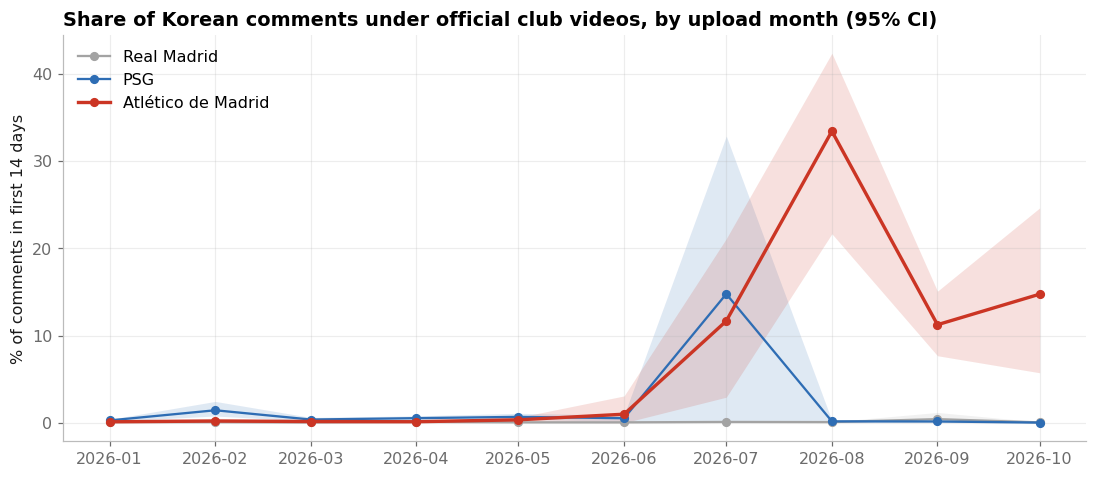

In [11]:
# Monthly view: is the Korean audience staying?
monthly = []
for (e, m), g in pv[pv.entity.isin(['atletico', 'psg', 'real_madrid'])].groupby(['entity', 'month']):
    b = share_boot(g, n=1000)
    monthly.append({'entity': e, 'month': m, 'share_%': 100 * b['share'], 'lo': 100 * b['lo'], 'hi': 100 * b['hi'],
                    'videos': b['videos'], 'korean_comments': b['ko']})
monthly = pd.DataFrame(monthly)
monthly['partial'] = monthly.month == CUTOFF.tz_convert(None).to_period('M')
display(monthly[monthly.entity == 'atletico'].round(2))

fig, ax = plt.subplots(figsize=(12, 4.8))
for e, col in [('real_madrid', GREY), ('psg', BLUE), ('atletico', RED)]:
    m = monthly[monthly.entity == e]
    x = m.month.dt.to_timestamp()
    ax.fill_between(x, m.lo, m.hi, color=col, alpha=0.15, lw=0)
    ax.plot(x, m['share_%'], color=col, lw=2.2 if e == 'atletico' else 1.5, marker='o', ms=5, label=LABEL[e])
ax.set_title('Share of Korean comments under official club videos, by upload month (95% CI)')
ax.set_ylabel('% of comments in first 14 days')
ax.legend(loc='upper left')
save(fig, 'diag_04_youtube_monthly')
plt.show()

## 5. Country placebo — Google Trends

If the signing caused the effect, Atlético's search interest (relative to the control clubs) should rise **in Korea** and not in the US or Japan. The US and Japan act as placebo markets: they had the same World Cup and the same LaLiga results, but no Korean player.

Metric per country: `Σ Atlético ÷ Σ controls` in each period (weekly data). Change = post ÷ pre − 1. Intervals: bootstrap of weeks within each period.

In [12]:
wk = trends[trends.granularity == 'weekly']
POST_START, POST_END = pd.Timestamp(SIGNING), COLLECTION.tz_convert(None) - pd.Timedelta(days=7)
rng = np.random.default_rng(SEED)
country = {}
for geo in ['KR', 'US', 'JP']:
    g = wk[wk.geo == geo].pivot_table(index='date', columns='entity', values='interest')
    if g.empty or 'atletico' not in g:
        continue
    ctrl = g[[c for c in CONTROLS if c in g]].sum(axis=1)
    pre = g.loc[PRE_PERIOD[0]:PRE_PERIOD[1]].index
    post = g.loc[POST_START:POST_END].index
    def ratio(ix):
        return g.loc[ix, 'atletico'].to_numpy().sum() / max(ctrl.loc[ix].to_numpy().sum(), 1e-9)
    pre_i = rng.integers(0, len(pre), (N_BOOT, len(pre)))
    post_i = rng.integers(0, len(post), (N_BOOT, len(post)))
    a, c = g['atletico'], ctrl
    rp = a.loc[pre].to_numpy()[pre_i].sum(1) / c.loc[pre].to_numpy()[pre_i].sum(1)
    rq = a.loc[post].to_numpy()[post_i].sum(1) / c.loc[post].to_numpy()[post_i].sum(1)
    country[geo] = {'change': 100 * (ratio(post) / ratio(pre) - 1), 'sample': 100 * (rq / rp - 1)}

trend_tbl = pd.DataFrame({geo: {'change_%': v['change'], 'ci_lo_%': np.percentile(v['sample'], 2.5),
                                'ci_hi_%': np.percentile(v['sample'], 97.5)} for geo, v in country.items()}).T
display(trend_tbl.round(1))

if {'KR', 'US', 'JP'} <= set(country):
    kr = 1 + country['KR']['sample'] / 100
    others = (1 + country['US']['sample'] / 100 + 1 + country['JP']['sample'] / 100) / 2
    rel = 100 * (kr / others - 1)
    TREND_DID = {'pct': float(np.median(rel)), 'lo': float(np.percentile(rel, 2.5)), 'hi': float(np.percentile(rel, 97.5))}
    print(f"Korea vs. placebo markets (US, JP): {TREND_DID['pct']:+.0f}% (95% CI {TREND_DID['lo']:+.0f}% to {TREND_DID['hi']:+.0f}%)")

,change_%,ci_lo_%,ci_hi_%
KR,92.3,33.9,194.4
US,-59.9,-73.7,-36.5
JP,-33.9,-53.7,-4.8


Korea vs. placebo markets (US, JP): +261% (95% CI +127% to +496%)


## 6. LinkedIn charts (1080 × 1350, portrait 4:5)

Three charts, one idea each, readable on a phone:

1. **The headline:** Korean share of comments, before vs. after, Atlético vs. the controls.
2. **The proof:** actual vs. counterfactual on Korean Wikipedia, with the extra visits quantified.
3. **The placebo:** the effect appears in Korea and not in the US or Japan.

Change `CHART_LANG` at the top to switch between Spanish and English.

In [21]:
def li_canvas(title, subtitle, source, left=0.10):
    fig = plt.figure(figsize=(10.8, 13.5), dpi=100, facecolor='white')
    fig.text(0.07, 0.95, title, fontsize=28, fontweight='bold', color=INK, va='top', linespacing=1.15)
    fig.text(0.07, 0.80, subtitle, fontsize=19, color=MUTED, va='top', linespacing=1.35)
    fig.text(0.07, 0.025, source, fontsize=12.5, color=MUTED, va='bottom', linespacing=1.4)
    fig.text(0.93, 0.085, AUTHOR, fontsize=14, color=INK, fontweight='bold', ha='right', va='bottom')
    ax = fig.add_axes([left, 0.16, 0.92 - left, 0.57])
    for s in ('top', 'right'):
        ax.spines[s].set_visible(False)
    ax.tick_params(labelsize=16, colors=MUTED)
    return fig, ax

Saved /content/drive/MyDrive/proyecto_kangin/kangin_lee_effect/phase2/figures/linkedin_1_headline.png


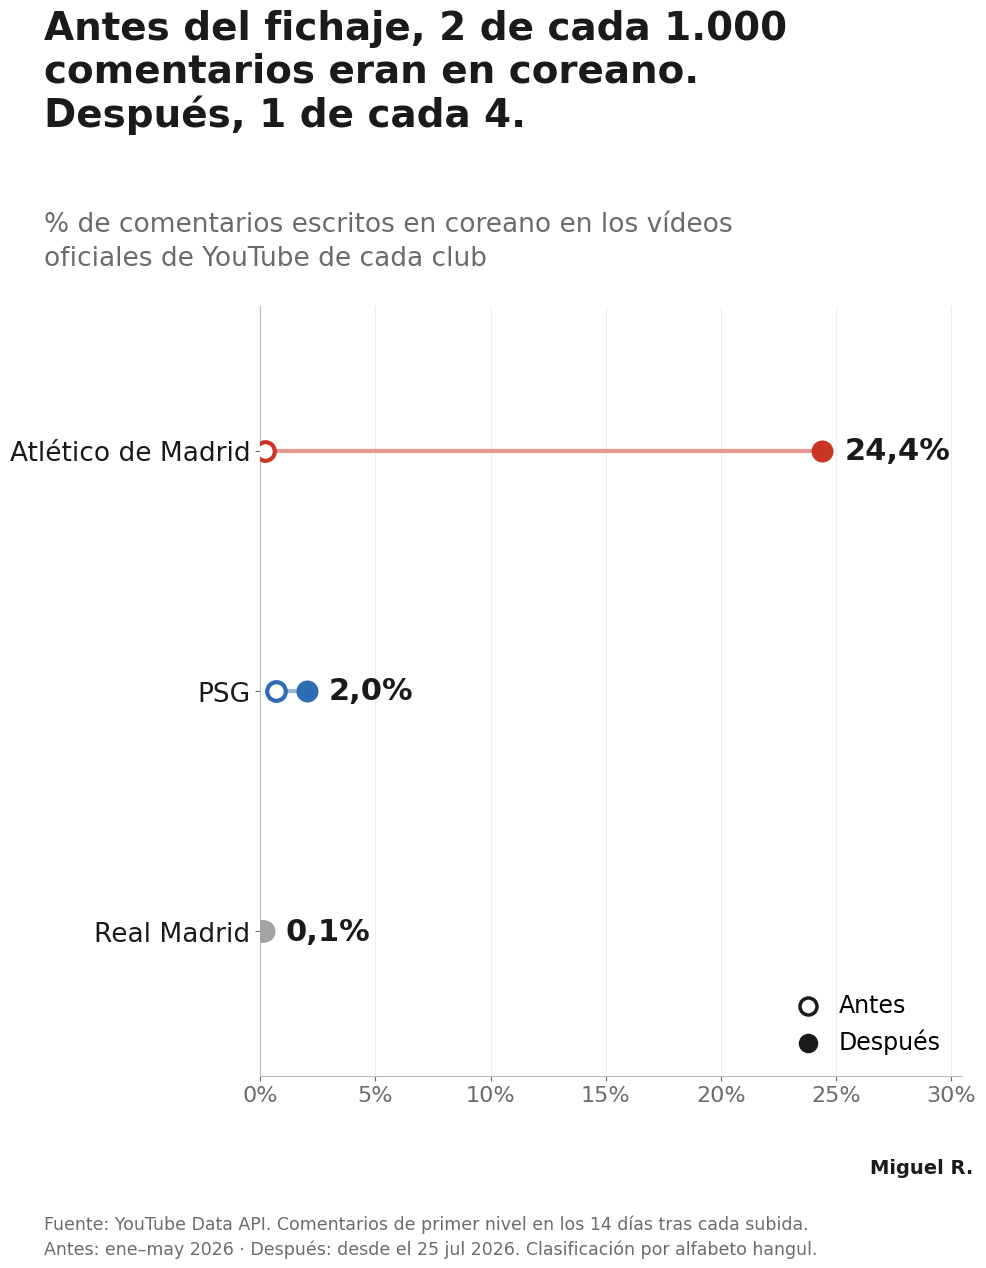

In [22]:
# Chart 1 — the headline
pre_s, post_s = 100 * B['atletico', 'pre']['share'], 100 * B['atletico', 'post']['share']
per_1000 = pre_s * 10
one_in = round(100 / post_s) if post_s > 0 else float('nan')

title = t(f'Antes del fichaje, {num(per_1000, 0)} de cada 1.000\ncomentarios eran en coreano.\nDespués, 1 de cada {one_in}.',
          f'Before the signing, {num(per_1000, 0)} in 1,000\ncomments were in Korean.\nAfter it, 1 in {one_in}.')
subtitle = t('% de comentarios escritos en coreano en los vídeos\noficiales de YouTube de cada club',
             'Share of comments written in Korean under each\nclub\'s official YouTube videos')
source = t(f'Fuente: YouTube Data API. Comentarios de primer nivel en los 14 días tras cada subida.\n'
           f'Antes: ene–may 2026 · Después: desde el 25 jul 2026. Clasificación por alfabeto hangul.',
           f'Source: YouTube Data API. Top-level comments within 14 days of upload.\n'
           f'Before: Jan–May 2026 · After: from 25 Jul 2026. Hangul-script classifier.')
fig, ax = li_canvas(title, subtitle, source, left=0.27)

clubs =['real_madrid', 'psg', 'atletico']
colors = {'atletico': RED, 'psg': BLUE, 'real_madrid': GREY}
for i, e in enumerate(clubs):
    a, b = 100 * B[e, 'pre']['share'], 100 * B[e, 'post']['share']
    ax.plot([a, b], [i, i], color=colors[e], lw=3, alpha=0.5, zorder=1)
    ax.scatter([a], [i], s=180, facecolor='white', edgecolor=colors[e], lw=3, zorder=3)
    ax.scatter([b], [i], s=220, color=colors[e], zorder=3)
    ax.annotate(pct(b), (max(a, b), i), xytext=(16, 0), textcoords='offset points', va='center',
                fontsize=22, fontweight='bold', color=INK)
ax.set_yticks(range(len(clubs)), [LABEL[c] for c in clubs], fontsize=19, color=INK)
ax.set_ylim(-0.6, len(clubs) - 0.4)
ax.set_xlim(0, max(28, post_s * 1.25))
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: pct(v, 0)))
ax.grid(axis='y', visible=False)
ax.scatter([], [], s=150, facecolor='white', edgecolor=INK, lw=2.5, label=t('Antes', 'Before'))
ax.scatter([], [], s=170, color=INK, label=t('Después', 'After'))
ax.legend(loc='lower right', fontsize=17, handletextpad=0.3)
save(fig, 'linkedin_1_headline')
plt.show()

Saved /content/drive/MyDrive/proyecto_kangin/kangin_lee_effect/phase2/figures/linkedin_2_counterfactual.png


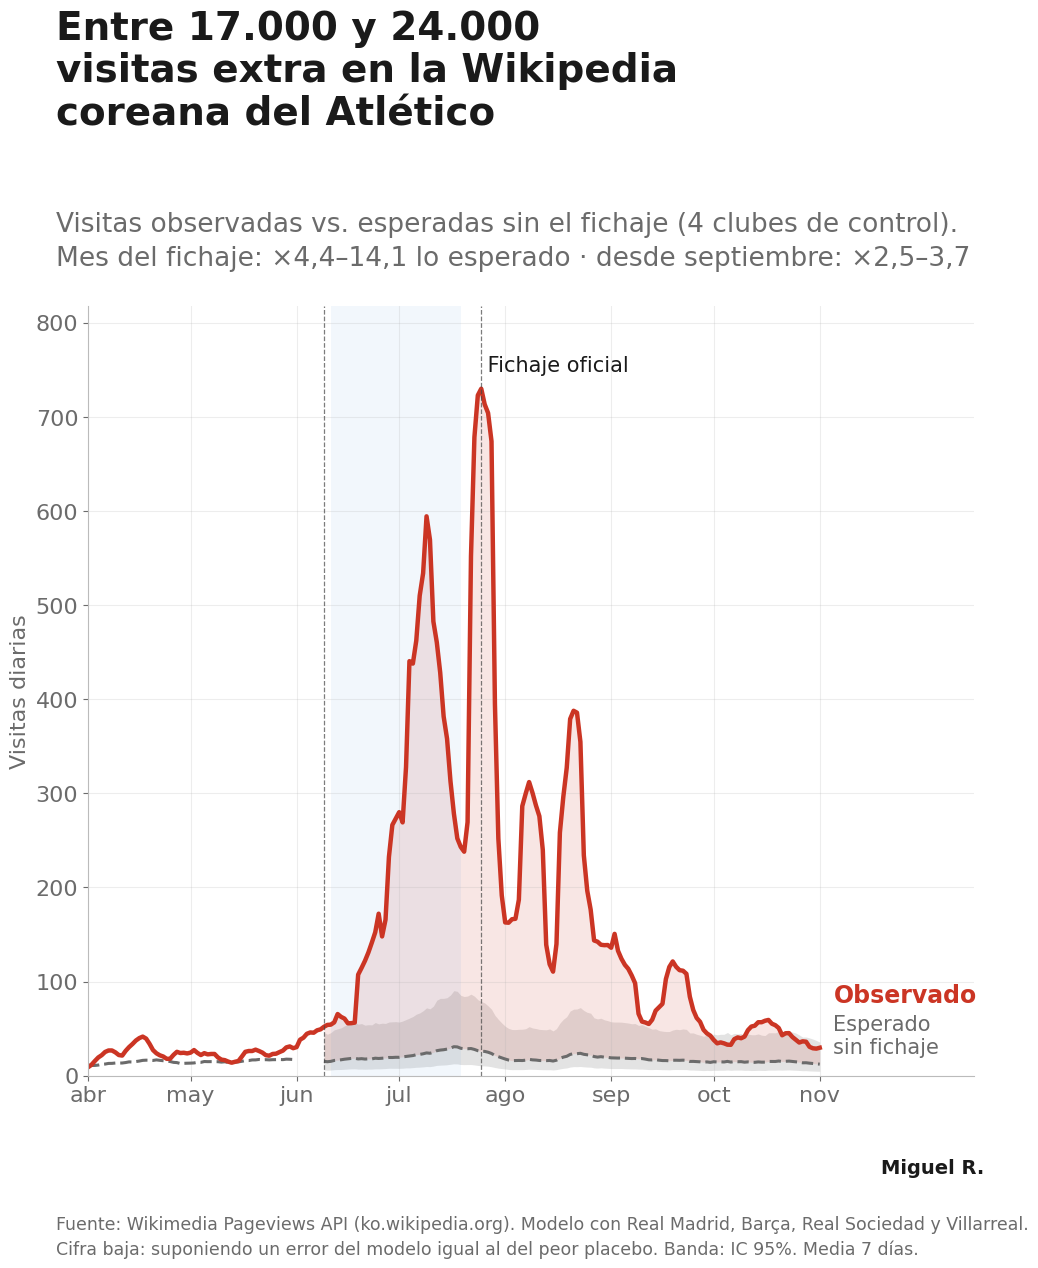

In [28]:
# Chart 2 — the proof (counterfactual)
tot = eff_main.loc['Total since rumours']
peak = eff_main.loc['Signing month']
persist = eff_main.loc['Persistence (Sep →)']
def worst_placebo(window):
    pl = placebo_space[(placebo_space.window == window) & ~placebo_space.club.str.contains('treated')]
    return max(pl.lift_pct.max(), 0) / 100

worst = worst_placebo('Signing month')
conservative = math.floor((tot.actual - tot.expected * (1 + worst)) / 1000) * 1000
low_peak = peak.actual / (peak.expected * (1 + worst))
low_persist = persist.actual / (persist.expected * (1 + worst_placebo('Persistence (Sep →)')))

title = t(f'Entre {num(conservative)} y {num(round(tot.extra, -3))}\nvisitas extra en la Wikipedia\ncoreana del Atlético',
          f'Between {num(conservative)} and {num(round(tot.extra, -3))}\nextra visits to Atlético\'s\nKorean Wikipedia page')
subtitle = t(f'Visitas observadas vs. esperadas sin el fichaje (4 clubes de control).\n'
             f'Mes del fichaje: ×{num(low_peak, 1)}–{num(peak.multiple, 1)} lo esperado · desde septiembre: ×{num(low_persist, 1)}–{num(persist.multiple, 1)}',
             f'Actual vs. expected without the signing (4 control clubs).\n'
             f'Signing month: ×{num(low_peak, 1)}–{num(peak.multiple, 1)} expected · since September: ×{num(low_persist, 1)}–{num(persist.multiple, 1)}')
source = t(f'Fuente: Wikimedia Pageviews API (ko.wikipedia.org). Modelo con Real Madrid, Barça, Real Sociedad y Villarreal.\n'
           f'Cifra baja: suponiendo un error del modelo igual al del peor placebo. Banda: IC 95%. Media 7 días.',
           f'Source: Wikimedia Pageviews API (ko.wikipedia.org). Model on Real Madrid, Barça, Real Sociedad and Villarreal.\n'
           f'Lower figure: assumes model error as large as the worst placebo. Band: 95% interval. 7-day avg.')
fig, ax = li_canvas(title, subtitle, source)

obs = ko['atletico'].loc['2026-04-01':END].rolling(7, center=True, min_periods=4).mean()
f = main['fitted'].loc['2026-04-01':].rolling(7, center=True, min_periods=4).mean()
p = main['post'].rolling(7, center=True, min_periods=4).mean()
ax.fill_between(p.index, p.cf_lo, p.cf_hi, color=GREY, alpha=0.3, lw=0)
ax.plot(f.index, f.fitted, color=MUTED, lw=2.2, ls='--')
ax.plot(p.index, p.cf_median, color=MUTED, lw=2.2, ls='--')
ax.fill_between(p.index, p.cf_median, p.actual, where=p.actual > p.cf_median, color=RED, alpha=0.12, lw=0)
ax.plot(obs.index, obs.values, color=RED, lw=3.2)
shade_events(ax, '2026-04-01', END)
ymax = obs.max()
ax.text(pd.Timestamp(SIGNING), ymax * 1.02, t(' Fichaje oficial', ' Official signing'), fontsize=15, color=INK, va='bottom')
# Direct labels at the right end of each line
last = p.dropna().index[-1]
ya, yc = p.actual.loc[last], p.cf_median.loc[last]
if ya - yc < ymax * 0.10:
    ya = yc + ymax * 0.10
ax.text(last + pd.Timedelta(days=4), ya, t('Observado', 'Observed'), color=RED, fontsize=17, fontweight='bold', va='center')
ax.text(last + pd.Timedelta(days=4), yc + ymax * 0.01, t('Esperado\nsin fichaje', 'Expected\nwithout him'), color=MUTED, fontsize=15, va='bottom')
ax.set_xlim(pd.Timestamp('2026-04-01'), last + pd.Timedelta(days=45))
ax.set_ylim(0, ymax * 1.12)
ax.set_ylabel(t('Visitas diarias', 'Daily pageviews'), fontsize=16, color=MUTED)
ax.set_xticks(list(pd.date_range('2026-04-01', last, freq='MS')))
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: t(
    ['ene', 'feb', 'mar', 'abr', 'may', 'jun', 'jul', 'ago', 'sep', 'oct', 'nov', 'dic'],
    ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'])[mdates.num2date(v).month - 1]))
save(fig, 'linkedin_2_counterfactual')
plt.show()

Saved /content/drive/MyDrive/proyecto_kangin/kangin_lee_effect/phase2/figures/linkedin_3_country_placebo.png


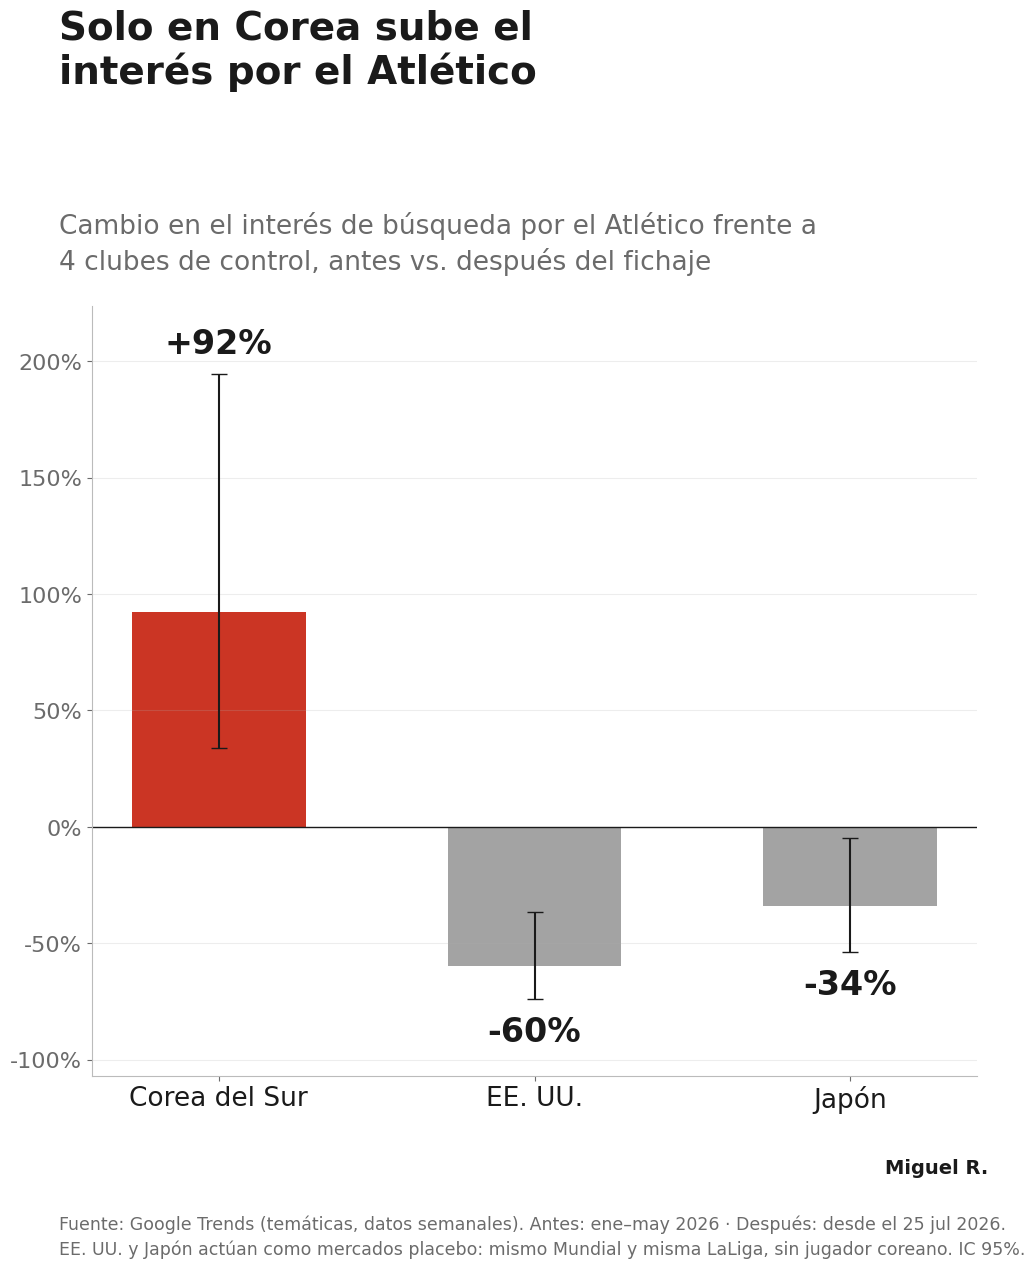

In [27]:
# Chart 3 — the country placebo
if country:
    kr_chg = trend_tbl.loc['KR', 'change_%']
    title = t('Solo en Corea sube el\ninterés por el Atlético', 'Only in Korea did interest\nin Atlético go up')
    subtitle = t('Cambio en el interés de búsqueda por el Atlético frente a\n4 clubes de control, antes vs. después del fichaje',
                 'Change in search interest for Atlético relative to 4 control\nclubs, before vs. after the signing')
    source = t('Fuente: Google Trends (temáticas, datos semanales). Antes: ene–may 2026 · Después: desde el 25 jul 2026.\n'
               'EE. UU. y Japón actúan como mercados placebo: mismo Mundial y misma LaLiga, sin jugador coreano. IC 95%.',
               'Source: Google Trends (topic entities, weekly). Before: Jan–May 2026 · After: from 25 Jul 2026.\n'
               'US and Japan act as placebo markets: same World Cup and LaLiga, no Korean player. 95% intervals.')
    fig, ax = li_canvas(title, subtitle, source)
    names = {'KR': t('Corea del Sur', 'South Korea'), 'US': t('EE. UU.', 'United States'), 'JP': t('Japón', 'Japan')}
    order = [g for g in ['KR', 'US', 'JP'] if g in trend_tbl.index]
    vals = trend_tbl.loc[order]
    x = np.arange(len(order))
    ax.bar(x, vals['change_%'], width=0.55, color=[RED if g == 'KR' else GREY for g in order])
    ax.errorbar(x, vals['change_%'], yerr=[vals['change_%'] - vals['ci_lo_%'], vals['ci_hi_%'] - vals['change_%']],
                fmt='none', ecolor=INK, elinewidth=1.5, capsize=6)
    for xi, v, lo, hi in zip(x, vals['change_%'], vals['ci_lo_%'], vals['ci_hi_%']):
      ax.annotate(('+' if v > 0 else '') + pct(v, 0), (xi, hi if v > 0 else lo),
                xytext=(0, 10 if v > 0 else -12), textcoords='offset points',
                ha='center', va='bottom' if v > 0 else 'top', fontsize=24, fontweight='bold', color=INK)
    ax.axhline(0, color=INK, lw=1)
    ax.set_ylim(vals['ci_lo_%'].min() * 1.45 if vals['ci_lo_%'].min() < 0 else 0, vals['ci_hi_%'].max() * 1.15)
    ax.set_xticks(x, [names[g] for g in order], fontsize=19, color=INK)
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: pct(v, 0)))
    ax.grid(axis='x', visible=False)
    save(fig, 'linkedin_3_country_placebo')
    plt.show()

## 7. Key numbers and caveats

Everything a reader could ask about, in one table, saved to `phase2/results_summary.csv`. Use only these numbers in the post.

In [17]:
summary = [
    ('Wikipedia KO · extra visits since rumours', tot.extra, tot.extra_lo, tot.extra_hi, 'visits'),
    ('Wikipedia KO · signing month, actual ÷ expected', peak.multiple, None, None, '×'),
    ('Wikipedia KO · signing month lift', peak.lift_pct, peak.lift_lo, peak.lift_hi, '%'),
    ('Wikipedia KO · persistence (Sep →) lift', persist.lift_pct, persist.lift_lo, persist.lift_hi, '%'),
    ('Wikipedia KO · model fit R² (log)', main['r2_log'], None, None, ''),
    ('Validation 2023 · PSG transfer-month lift', eff_val.iloc[0].lift_pct, eff_val.iloc[0].lift_lo, eff_val.iloc[0].lift_hi, '%'),
    ('YouTube · Atlético Korean share, pre', pre_s, 100 * B['atletico', 'pre']['lo'], 100 * B['atletico', 'pre']['hi'], '%'),
    ('YouTube · Atlético Korean share, post', post_s, 100 * B['atletico', 'post']['lo'], 100 * B['atletico', 'post']['hi'], '%'),
    ('YouTube · DiD vs Real Madrid', DID['pp'], DID['lo'], DID['hi'], 'pp'),
    ('YouTube · Atlético post, videos without Lee', segments.iloc[2]['share_%'], segments.iloc[2]['ci_lo_%'], segments.iloc[2]['ci_hi_%'], '%'),
]
if 'TREND_DID' in globals():
    summary.append(('Trends · Korea vs US/JP relative change', TREND_DID['pct'], TREND_DID['lo'], TREND_DID['hi'], '%'))
summary = pd.DataFrame(summary, columns=['metric', 'estimate', 'ci_95_lo', 'ci_95_hi', 'unit'])
summary.to_csv(OUT / 'results_summary.csv', index=False)
eff_main.to_csv(OUT / 'wikipedia_effects.csv')
placebo_space.to_csv(OUT / 'placebo_space.csv', index=False)
yt_table.to_csv(OUT / 'youtube_did_table.csv', index=False)
display(summary.round(2))
print('Saved to', OUT)

,metric,estimate,ci_95_lo,ci_95_hi,unit
0,Wikipedia KO · extra visits since rumours,24340.71,23702.92,24846.98,visits
1,"Wikipedia KO · signing month, actual ÷ expected",14.14,NaN,NaN,×
2,Wikipedia KO · signing month lift,1313.58,883.51,1805.01,%
3,Wikipedia KO · persistence (Sep →) lift,265.25,176.45,364.56,%
4,Wikipedia KO · model fit R² (log),0.18,NaN,NaN,
5,Validation 2023 · PSG transfer-month lift,382.86,208.75,508.09,%
6,"YouTube · Atlético Korean share, pre",0.18,0.11,0.28,%
7,"YouTube · Atlético Korean share, post",24.39,16.59,31.25,%
8,YouTube · DiD vs Real Madrid,23.70,16.35,31.07,pp
9,"YouTube · Atlético post, videos without Lee",8.56,6.59,10.77,%


Saved to /content/drive/MyDrive/proyecto_kangin/kangin_lee_effect/phase2


### Caveats to keep in the post (they make it more credible, not less)

1. **Attention, not revenue.** These are proxies for awareness among Korean-speaking audiences. Shirt sales and commercial income are not public.
2. **Comment language ≠ nationality.** Korean-language comments are a proxy for the Korean-speaking audience, which includes the diaspora.
3. **Counterfactual assumptions.** The model assumes that, without the signing, Atlético would have kept its pre-2026 relationship with the control clubs. The placebo tests support this, but they cannot prove it.
4. **Other things happened.** Pre-season activity, match results and the player's form also move attention. The country placebo (US/JP) and the control clubs absorb the common shocks, not the Atlético-specific ones.
5. **Validation case.** The 2023 PSG case confirms the pattern but has its own confounders (PSG's Asian tour).